# Ethics Statements and Data Sharing -- Longitudinal Analysis 2011-2025

## Background: JATS4R Ethics Statement Recommendation

The **JATS4R Ethics Statement recommendation** (published **1 April 2020**,
DOI 10.3789/niso-rp-33-2020) standardises how ethical declarations are
machine-tagged in JATS XML. Subgroup members: David Haber (ASM),
Amber Gunn & Aradhana Mistry (BMJ), Melissa Harrison (eLife),
Lucie Senn (Frontiers, Chair), Jonathan Watson (Emerald).

Ethics statements cover:
- IRB / ethics committee approvals (local, regional, national review bodies)
- Informed consent declarations (written, verbal, parental, consent-to-publish)
- Declaration of Helsinki / ICMJE compliance
- IACUC / animal care committee approvals
- Data anonymisation and handling of confidential patient data

### JATS4R normative rules

| Rule | Requirement | Validator result |
|------|-------------|------------------|
| R1 | Ethics section in `<sec>` (use `<title>` not `<label>`) | WARNING if label without title |
| R2 | `sec-type="ethics-statement"` -- exact value | ERROR for any mistyped variant |
| R3a | Sub-sections: `sec-type="ethics-<value>"` | ERROR if nested sec-type not `ethics-` prefixed |
| R3b | Paragraph-level: `content-type="ethics-<value>"` | ERROR if not `ethics-` prefixed |
| R4 | Inline flow: `content-type="ethics-statement"` | WARNING (least preferred) |

Suggested sub-values: `ethics-consent-to-publish`, `ethics-review-body`,
`ethics-approval`, `ethics-approval-human`, `ethics-approval-animal`.

---

## Research questions

1. Do articles with ethics statements share data at a higher rate?
2. Does ethics sub-type (human/animal/IRB/consent) predict data-sharing behaviour?
3. Have ethics statements and DAS co-evolved since the 2016 FAIR principles paper?
4. Does JATS4R-compliant ethics tagging correlate with JATS4R-compliant DAS tagging?
5. Which publishers and disciplines lead on ethics + data sharing co-occurrence?

---

## Data source

Ethics statements are read directly from the `ethics_statement` and
`ethics_sub_type` tables in the database -- populated once by
`pipeline/extract_ethics.py` (Stage), which parses the raw PMC XML using the
same priority cascade as `_extract_das()` in `pubmed_to_sqlite.py`, adapted
for the JATS4R ethics spec. This notebook does no XML parsing itself; it
joins the pre-populated ethics tables to `das_category`, `data_availability`,
`article`, `journal`, and Stage 6 tables.

| Section | Content |
|---------|--------|
| 0 | Setup, compliance classifier |
| 1 | Build master frame from DB |
| 2 | Ethics statement prevalence over time |
| 3 | JATS4R compliance tier for ethics tagging |
| 4 | sec-type value zoo (top-level tag, from `ethics_statement`) |
| 5 | Ethics sub-type tagging (nested tags, from `ethics_sub_type`) |
| 6 | Ethics sub-type signals (IRB / consent / human / animal, keyword-derived) |
| 7 | Ethics presence vs DAS presence and data-sharing score |
| 8 | Ethics sub-type vs data-sharing behaviour |
| 9 | Co-evolution: ethics + DAS over time |
| 10 | JATS4R ethics compliance vs DAS compliance |
| 11 | Ethics statement verbosity and text content |
| 12 | Publisher league table |
| 13 | Discipline breakdown (Stage 6) |
| 14 | Four-period analysis + statistical summary + exports |


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


---
## Section 0 -- Setup, Compliance Classifier, Master Frame

In [2]:
import sqlite3, re, warnings, importlib
import matplotlib; importlib.reload(matplotlib)
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')
importlib.reload(matplotlib); plt = matplotlib.pyplot
sns.set_theme(style='whitegrid', font_scale=1.15)

DB_PATH = Path('../data/processed/pmc_fair.db')
FIG_W, FIG_H = 13, 5

assert DB_PATH.exists(), f'Database not found at {DB_PATH.resolve()}'
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row

def qdb(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

tables = {r[0] for r in con.execute(
    "SELECT name FROM sqlite_master WHERE type='table'").fetchall()}
HAS_DISC   = 'article_discipline' in tables
HAS_FUNDER = 'article_funder'     in tables
HAS_OA     = 'journal_oa'         in tables

print('Tables in DB:', sorted(tables))
print('Discipline (Stage 6):', 'yes' if HAS_DISC   else 'no')
print('Funder     (Stage 6):', 'yes' if HAS_FUNDER else 'no')
print('OA status  (Stage 6):', 'yes' if HAS_OA     else 'no')

n_ethics = con.execute('SELECT COUNT(*) FROM ethics_statement').fetchone()[0] \
    if 'ethics_statement' in tables else 0
if n_ethics == 0:
    print('⚠️  ethics_statement table is empty -- run pipeline/extract_ethics.py first.')
else:
    print(f'✅ ethics_statement: {n_ethics:,} rows (from pipeline/extract_ethics.py)')

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


Tables in DB: ['accession_number', 'affiliation', 'article', 'article_author', 'article_discipline', 'article_funder', 'article_keyword', 'article_mesh', 'author', 'author_affiliation', 'code_availability', 'code_link', 'da_link', 'das_category', 'data_availability', 'ethics_statement', 'ethics_sub_type', 'fuji_article_link', 'fuji_assessment', 'fuji_metric', 'given_name_gender', 'journal', 'journal_oa', 'keyword', 'link_rot', 'link_rot_run', 'repo_classification', 'sqlite_sequence', 'supplementary_material']
Discipline (Stage 6): yes
Funder     (Stage 6): yes
OA status  (Stage 6): yes


✅ ethics_statement: 1,245,851 rows (from pipeline/extract_ethics.py)


### Compliance classifiers

The ethics extractor (`pipeline/extract_ethics.py`) writes `ethics_statement.source`
strings in exactly the same format as `data_availability.source` in the pipeline.
This lets us apply the same tier logic to both columns.

| `source` value | JATS4R tier |
|----------------|-------------|
| `sec[@sec-type='ethics-statement']` | **compliant** |
| `sec[@sec-type='<any other ethics value>']` | near_miss |
| `sec/title='<heading text>'` | title_only |
| `p[@content-type='ethics-...']` or `named-content[...]` | inline |
| empty | no_ethics |


In [3]:
# ── Ethics compliance classifier ────────────────────────────────────────────
_E_SECTYPE_RE = re.compile(r"^sec\[@sec-type='(.+)'\]$")
_E_TITLE_RE   = re.compile(r"^sec/title='(.+)'$")

JATS4R_EXACT_ETHICS = "sec[@sec-type='ethics-statement']"

def classify_ethics(source):
    s = str(source or '').strip()
    if not s:                            return 'no_ethics'
    if s == JATS4R_EXACT_ETHICS:         return 'compliant'
    if _E_SECTYPE_RE.match(s):           return 'near_miss'
    if _E_TITLE_RE.match(s):             return 'title_only'
    if s.startswith('p[@content-type='): return 'inline'
    if s.startswith('named-content['):   return 'inline'
    return 'non_standard'

def eth_sectype_val(source):
    m = _E_SECTYPE_RE.match(str(source or ''))
    return m.group(1) if m else None

def eth_title_val(source):
    m = _E_TITLE_RE.match(str(source or ''))
    return m.group(1) if m else None

# ── DAS compliance classifier (mirrors fair_jats4r_compliance.ipynb) ────────
_D_SECTYPE_RE = re.compile(r"^sec\[@sec-type='(.+)'\]$")

def classify_das(source):
    s = str(source or '').strip()
    if not s: return 'no_das'
    if s == "sec[@sec-type='data-availability']": return 'compliant'
    if _D_SECTYPE_RE.match(s):   return 'near_miss'
    if s == 'data-availability element': return 'near_miss'
    if re.match(r'^sec/title=', s): return 'title_only'
    return 'non_standard'

# palette and ordering
ETH_ORDER = ['compliant','near_miss','title_only','inline','non_standard','no_ethics']
ETH_LABEL = {
    'compliant':    'Compliant  (sec-type="ethics-statement")',
    'near_miss':    'Near-miss  (wrong sec-type variant)',
    'title_only':   'Title-only (found by heading text)',
    'inline':       'Inline     (p / named-content content-type)',
    'non_standard': 'Non-standard',
    'no_ethics':    'No ethics statement found',
}
ETH_PAL = {
    'compliant':'#2ca02c', 'near_miss':'#ff7f0e', 'title_only':'#1f77b4',
    'inline':'#9467bd', 'non_standard':'#8c564b', 'no_ethics':'#d3d3d3',
}

# self-test
assert classify_ethics(JATS4R_EXACT_ETHICS)                       == 'compliant'
assert classify_ethics("sec[@sec-type='Ethics-Statement']")       == 'near_miss'
assert classify_ethics("sec/title='Ethics'")                      == 'title_only'
assert classify_ethics("p[@content-type='ethics-approval']")      == 'inline'
assert classify_ethics('')                                         == 'no_ethics'
print('Compliance classifiers OK.')
print('  Exact JATS4R ethics source:', JATS4R_EXACT_ETHICS)


Compliance classifiers OK.
  Exact JATS4R ethics source: sec[@sec-type='ethics-statement']


---
## Section 1 -- Build Master Frame

In [4]:
df = qdb("""
    SELECT
        a.article_id,
        a.year          AS year,
        a.journal_id,
        a.article_type,
        -- ethics columns
        COALESCE(es.source,'')           AS eth_source,
        COALESCE(es.statement,'')        AS eth_text,
        COALESCE(es.word_count,0)        AS eth_words,
        COALESCE(es.sentence_count,0)    AS eth_sents,
        COALESCE(es.has_irb,0)           AS has_irb,
        COALESCE(es.has_consent,0)       AS has_consent,
        COALESCE(es.has_helsinki,0)      AS has_helsinki,
        COALESCE(es.has_human,0)         AS has_human,
        COALESCE(es.has_animal,0)        AS has_animal,
        COALESCE(es.has_waived,0)        AS has_waived,
        COALESCE(es.has_approval_num,0)  AS has_approval_num,
        COALESCE(es.has_data_anon,0)     AS has_data_anon,
        -- DAS columns
        COALESCE(da.source,'')           AS das_source,
        COALESCE(da.statement,'')        AS das_text,
        -- DAS quality
        dc.data_sharing_score,
        dc.primary_category              AS das_cat,
        COALESCE(dc.mentions_license,0)  AS mentions_license,
        COALESCE(dc.mentions_doi,0)      AS mentions_doi,
        COALESCE(dc.has_url,0)           AS has_url,
        COALESCE(dc.has_accession,0)     AS has_accession,
        COALESCE(dc.word_count,0)        AS das_words
    FROM article a
    LEFT JOIN ethics_statement  es ON es.article_id = a.article_id
    LEFT JOIN data_availability da ON da.article_id = a.article_id
    JOIN      das_category      dc ON dc.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

df['has_ethics'] = df['eth_source'].str.strip().ne('')
df['has_das']    = df['das_source'].str.strip().ne('')
df['both']       = df['has_ethics'] & df['has_das']
df['eth_tier']   = df['eth_source'].apply(classify_ethics)
df['das_tier']   = df['das_source'].apply(classify_das)
df['eth_stval']  = df['eth_source'].apply(eth_sectype_val)
df['eth_ttval']  = df['eth_source'].apply(eth_title_val)
df['period']     = df['year'].apply(
    lambda y: 'Pre-FAIR (2011-15)'       if y < 2016
         else 'FAIR year (2016)'          if y == 2016
         else 'Post-FAIR/pre-rec (17-18)' if y <= 2018
         else 'Post-rec (2019-24)')

jrnl = qdb('SELECT journal_id, title AS jrnl_title, publisher FROM journal')
df   = df.merge(jrnl, on='journal_id', how='left')

n = len(df)
print(f'Master frame: {n:,} articles x {len(df.columns)} columns')
print(f'  Has ethics statement : {df["has_ethics"].sum():>9,}  ({df["has_ethics"].mean()*100:.1f}%)')
print(f'  Has DAS              : {df["has_das"].sum():>9,}  ({df["has_das"].mean()*100:.1f}%)')
print(f'  Has BOTH             : {df["both"].sum():>9,}  ({df["both"].mean()*100:.1f}%)')
print(f'  Has neither          : {(~df["has_ethics"] & ~df["has_das"]).sum():>9,}')


Master frame: 6,874,176 articles x 35 columns
  Has ethics statement : 1,244,659  (18.1%)
  Has DAS              : 3,011,043  (43.8%)
  Has BOTH             :   825,712  (12.0%)
  Has neither          : 3,444,186


---
## Section 2 -- Ethics Statement Prevalence Over Time

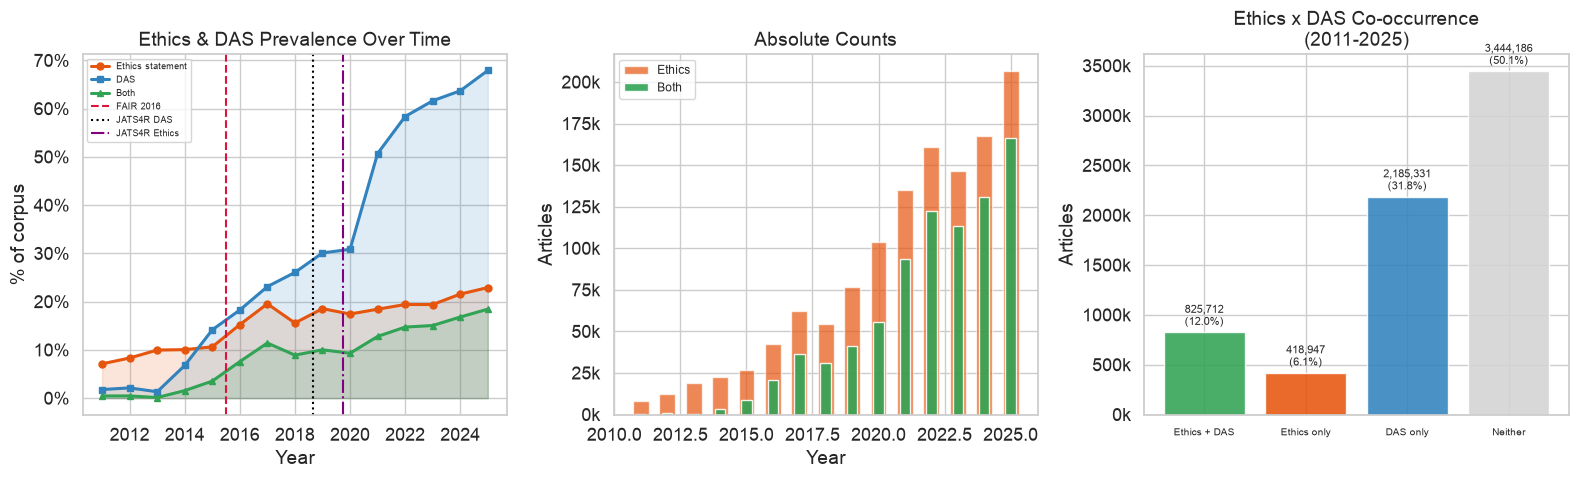

 year  n_total  n_eth  pct_eth  pct_das  pct_both
 2011   110347   7843      7.1      1.8       0.5
 2012   148267  12340      8.3      2.1       0.5
 2013   187212  18660     10.0      1.3       0.1
 2014   223496  22465     10.1      6.8       1.6
 2015   252745  26861     10.6     14.2       3.5
 2016   277445  42271     15.2     18.3       7.6
 2017   318654  62297     19.6     23.1      11.4
 2018   349018  54339     15.6     26.1       8.9
 2019   414163  76828     18.6     30.1      10.0
 2020   595499 103823     17.4     30.8       9.3
 2021   734002 135312     18.4     50.7      12.8
 2022   830189 161116     19.4     58.4      14.7
 2023   754942 146437     19.4     61.6      15.0
 2024   776984 167594     21.6     63.7      16.8
 2025   901213 206473     22.9     67.9      18.4


In [5]:
yr = (df.groupby('year').agg(
    n_total=('article_id','count'),
    n_eth  =('has_ethics','sum'),
    n_das  =('has_das','sum'),
    n_both =('both','sum'),
).reset_index())
yr['pct_eth']  = yr['n_eth']  / yr['n_total'] * 100
yr['pct_das']  = yr['n_das']  / yr['n_total'] * 100
yr['pct_both'] = yr['n_both'] / yr['n_total'] * 100

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H))

# Trend lines
ax = axes[0]
for col, clr, mrk, lbl in [
        ('pct_eth', '#e6550d', 'o', 'Ethics statement'),
        ('pct_das', '#3182bd', 's', 'DAS'),
        ('pct_both','#31a354', '^', 'Both')]:
    ax.fill_between(yr['year'], yr[col], alpha=0.15, color=clr)
    ax.plot(yr['year'], yr[col], lw=2.2, marker=mrk, ms=5, color=clr, label=lbl)
for xv, lbl, clr, ls in [
        (2015.5, 'FAIR 2016',       'crimson', '--'),
        (2018.67,'JATS4R DAS',      'black',   ':' ),
        (2019.75,'JATS4R Ethics',   'purple',  '-.' )]:
    ax.axvline(xv, color=clr, lw=1.5, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Year'); ax.set_ylabel('% of corpus')
ax.set_title('Ethics & DAS Prevalence Over Time')
ax.legend(fontsize=6.5)

# Absolute counts
ax = axes[1]
ax.bar(yr['year'], yr['n_eth'],  color='#e6550d', alpha=0.7, width=0.6, label='Ethics')
ax.bar(yr['year'], yr['n_both'], color='#31a354', alpha=0.9, width=0.4, label='Both')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{x/1e3:.0f}k'))
ax.set_xlabel('Year'); ax.set_ylabel('Articles')
ax.set_title('Absolute Counts')
ax.legend(fontsize=8.5)

# 2x2 co-occurrence
ax = axes[2]
groups = {
    'Ethics + DAS': int(df['both'].sum()),
    'Ethics only':  int((df['has_ethics'] & ~df['has_das']).sum()),
    'DAS only':     int((~df['has_ethics'] & df['has_das']).sum()),
    'Neither':      int((~df['has_ethics'] & ~df['has_das']).sum()),
}
bars = ax.bar(list(groups.keys()), list(groups.values()),
              color=['#31a354','#e6550d','#3182bd','#d3d3d3'],
              alpha=0.88, edgecolor='white')
ax.bar_label(bars,
             labels=[f'{v:,}\n({v/len(df)*100:.1f}%)' for v in groups.values()],
             padding=3, fontsize=8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{x/1e3:.0f}k'))
ax.set_ylabel('Articles')
ax.set_title('Ethics x DAS Co-occurrence\n(2011-2025)')
ax.tick_params(axis='x', labelsize=7.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth02_prevalence.png", **SAVEFIG_KWARGS)
plt.show()
print(yr[['year','n_total','n_eth','pct_eth','pct_das','pct_both']].round(1).to_string(index=False))


---
## Section 3 -- JATS4R Compliance Tier for Ethics Tagging

Ethics tagging compliance breakdown:
  Compliant  (sec-type="ethics-statement")                   141,400  (  2.1%)
  Near-miss  (wrong sec-type variant)                         14,021  (  0.2%)
  Title-only (found by heading text)                       1,062,859  ( 15.5%)
  Inline     (p / named-content content-type)                      0  (  0.0%)
  Non-standard                                                26,379  (  0.4%)
  No ethics statement found                                5,629,517  ( 81.9%)


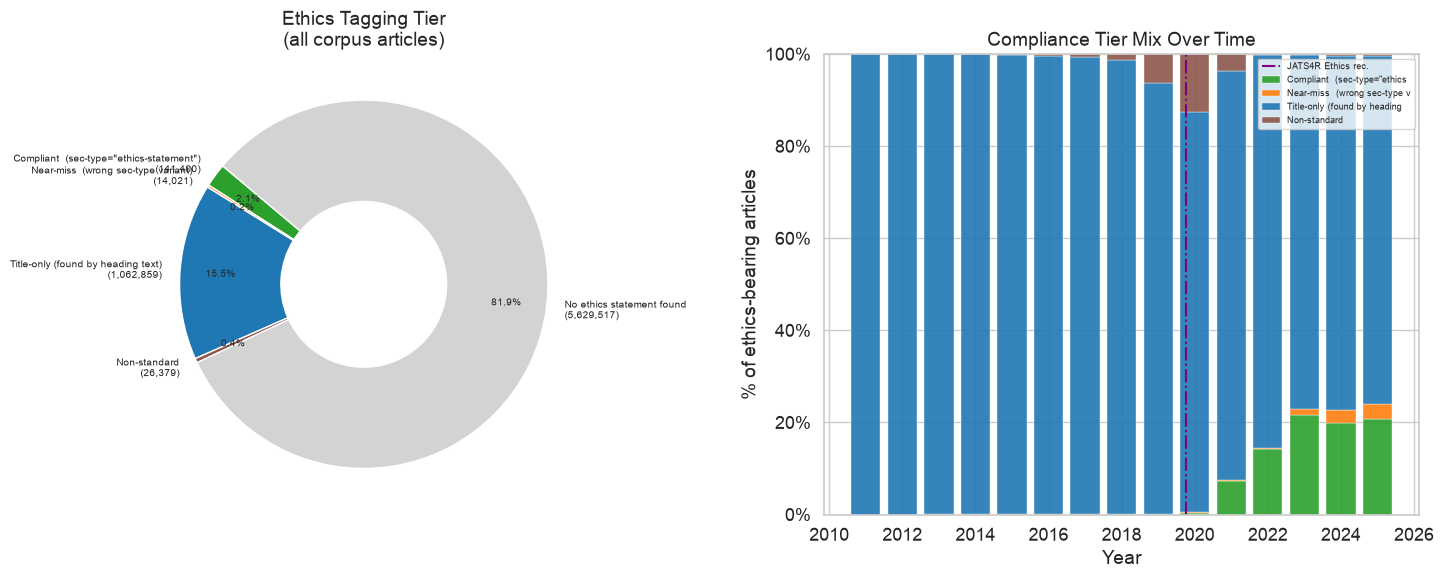

In [6]:
tier_vc = df['eth_tier'].value_counts().reindex(ETH_ORDER).fillna(0).astype(int)
print('Ethics tagging compliance breakdown:')
for k in ETH_ORDER:
    print(f'  {ETH_LABEL[k]:55}  {tier_vc[k]:>9,}  ({tier_vc[k]/len(df)*100:5.1f}%)')

# Year trend by tier (among ethics-bearing articles)
yr_tier = (df[df['has_ethics']].groupby(['year','eth_tier'])
           .size().reset_index(name='n'))
yr_eth_tot = df[df['has_ethics']].groupby('year').size()
yr_tier['pct'] = yr_tier.apply(
    lambda r: r['n'] / yr_eth_tot.get(r['year'], 1) * 100, axis=1)
piv = (yr_tier.pivot_table(index='year', columns='eth_tier',
                           values='pct', aggfunc='sum').fillna(0))

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 1))

# Donut
ax = axes[0]
vals = [tier_vc[k] for k in ETH_ORDER if tier_vc[k] > 0]
labs = [f'{ETH_LABEL[k]}\n({tier_vc[k]:,})' for k in ETH_ORDER if tier_vc[k] > 0]
ax.pie(vals, labels=labs, colors=[ETH_PAL[k] for k in ETH_ORDER if tier_vc[k] > 0],
       autopct='%1.1f%%', startangle=140, pctdistance=0.78,
       wedgeprops=dict(width=0.55), textprops={'fontsize':7})
ax.set_title('Ethics Tagging Tier\n(all corpus articles)')

# Stacked bar over time
ax = axes[1]
bot = np.zeros(len(piv))
for tier in ETH_ORDER:
    if tier not in piv.columns or tier == 'no_ethics': continue
    ax.bar(piv.index, piv[tier].values, bottom=bot,
           color=ETH_PAL[tier], label=ETH_LABEL[tier][:28],
           edgecolor='white', lw=0.3, alpha=0.9, width=0.8)
    bot += piv[tier].values
ax.axvline(2019.75, color='purple', lw=1.5, ls='-.', label='JATS4R Ethics rec.')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Year'); ax.set_ylabel('% of ethics-bearing articles')
ax.set_title('Compliance Tier Mix Over Time')
ax.legend(fontsize=6.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth03_compliance_tier.png", **SAVEFIG_KWARGS)
plt.show()


---
## Section 4 -- Ethics `sec-type` Value Zoo

What values do publishers actually write? The JATS4R validator flags
any value that is not exactly `"ethics-statement"` as an ERROR.


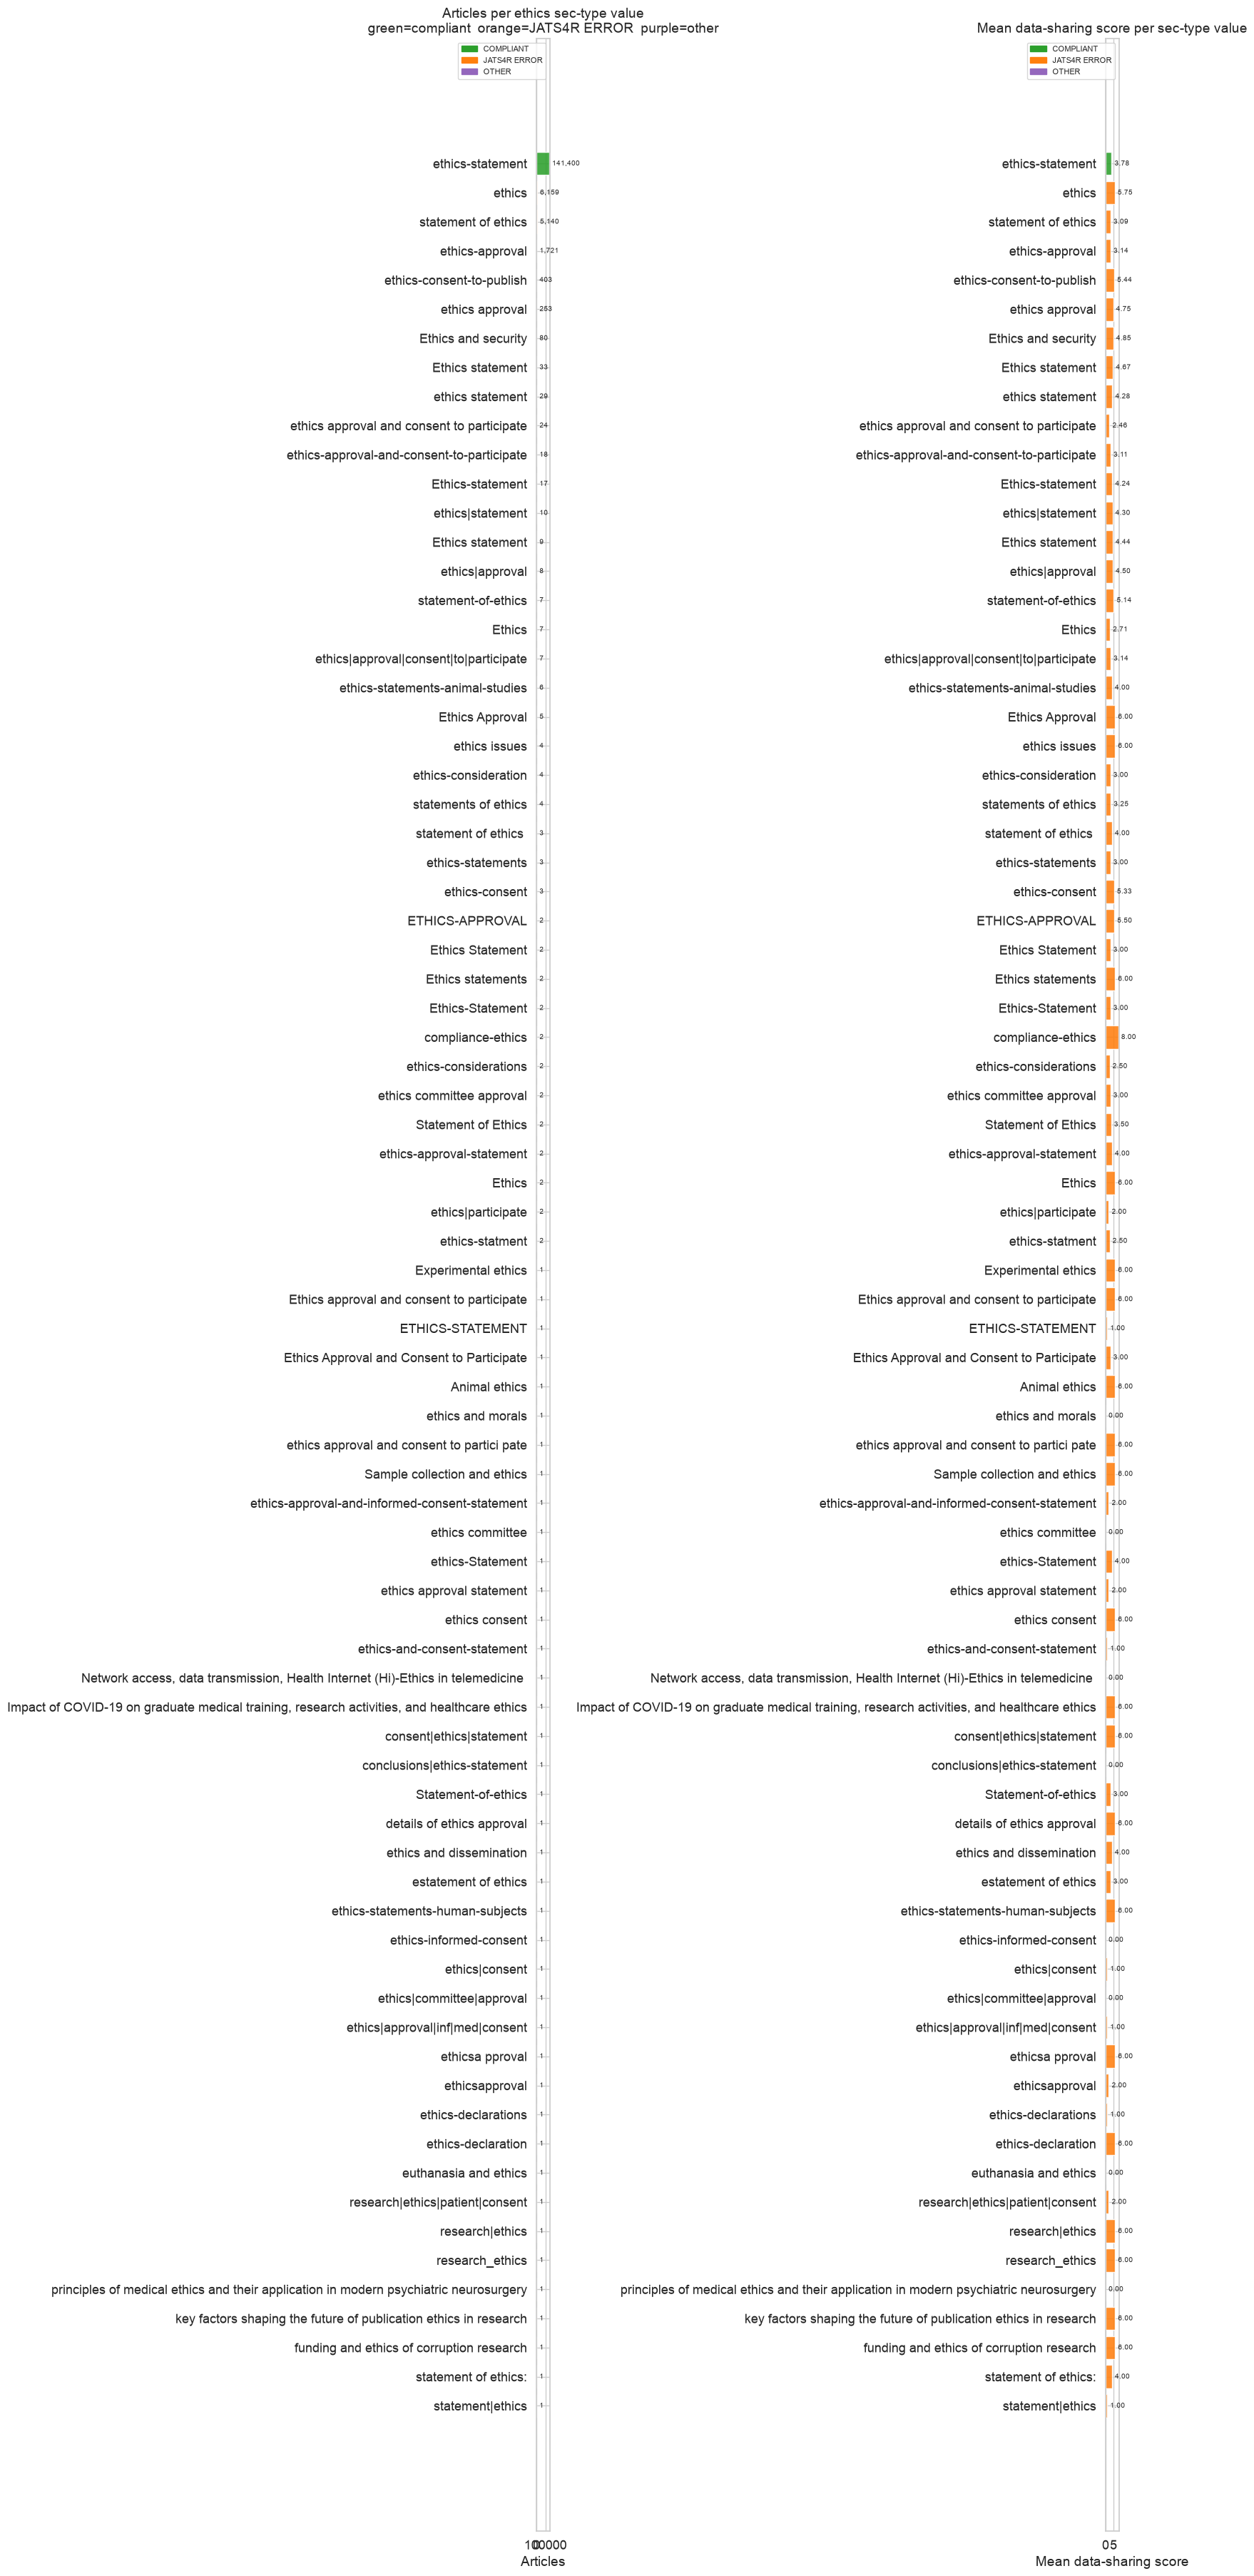

                                                                                  eth_stval      n   pct  mean_score       status
                                                                           ethics-statement 141400 2.057       3.783    COMPLIANT
                                                                                     ethics   6159 0.090       5.754 JATS4R ERROR
                                                                        statement of ethics   5140 0.075       3.086 JATS4R ERROR
                                                                            ethics-approval   1721 0.025       3.136 JATS4R ERROR
                                                                  ethics-consent-to-publish    403 0.006       5.439 JATS4R ERROR
                                                                            ethics approval    253 0.004       4.747 JATS4R ERROR
                                                                        Ethics and securit

In [7]:
st_eth = (
    df[df['eth_stval'].notna()]
    .groupby('eth_stval')
    .agg(n=('article_id','count'), mean_score=('data_sharing_score','mean'))
    .sort_values('n', ascending=False)
    .reset_index()
)
st_eth['pct']    = st_eth['n'] / len(df) * 100
st_eth['status'] = st_eth['eth_stval'].apply(
    lambda v: 'COMPLIANT'
    if v == 'ethics-statement'
    else ('JATS4R ERROR' if 'ethics' in v.lower() else 'OTHER'))
ST_PAL = {'COMPLIANT':'#2ca02c','JATS4R ERROR':'#ff7f0e','OTHER':'#9467bd'}

if len(st_eth) == 0:
    print('No sec-type values found -- all ethics detected by title or inline.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(FIG_W+3, max(5, len(st_eth)*0.44+2)))
    for ax, col, xlbl in [
            (axes[0], 'n',         'Articles'),
            (axes[1], 'mean_score', 'Mean data-sharing score')]:
        clrs = [ST_PAL[s] for s in st_eth['status'][::-1]]
        bars = ax.barh(st_eth['eth_stval'][::-1], st_eth[col][::-1],
                       color=clrs, alpha=0.88, edgecolor='white')
        ax.bar_label(bars,
                     labels=[f'{int(v):,}' if col=='n' else f'{v:.2f}'
                             for v in st_eth[col][::-1]],
                     padding=3, fontsize=7.5)
        ax.set_xlabel(xlbl)
        ax.legend(handles=[mpatches.Patch(color=c,label=l)
                            for l,c in ST_PAL.items()], fontsize=8)
    axes[0].set_title('Articles per ethics sec-type value\n'
                      'green=compliant  orange=JATS4R ERROR  purple=other')
    axes[1].set_title('Mean data-sharing score per sec-type value')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_eth04_sectype_zoo.png", **SAVEFIG_KWARGS)
    plt.show()
    print(st_eth[['eth_stval','n','pct','mean_score','status']].round(3).to_string(index=False))


---
## Section 5 -- Ethics Sub-Type Tagging (`ethics_sub_type` table)

JATS4R recommends nested ethics sub-sections use `sec-type="ethics-<value>"`, with suggested
values `ethics-consent-to-publish`, `ethics-review-body`, `ethics-approval`,
`ethics-approval-human`, `ethics-approval-animal`. `ethics_sub_type` records every such
nested tag actually found -- whether it's a properly-typed `sec-type`, a heading found only by
its `<title>` text (`sec-title`), or a paragraph-level `content-type` attribute
(`p-content-type`). This is the sub-section equivalent of Section 4's top-level `sec-type`
zoo, and -- unlike Section 7's classifier-derived keyword signals -- reads directly from the
structured tags authors/publishers actually used.

Total nested ethics sub-tags found: 124,063
  sec-title (heading text only)      73,260  (59.1%)
  p-content-type (paragraph-level)   43,378  (35.0%)
  sec-type (properly tagged)          7,425  ( 6.0%)


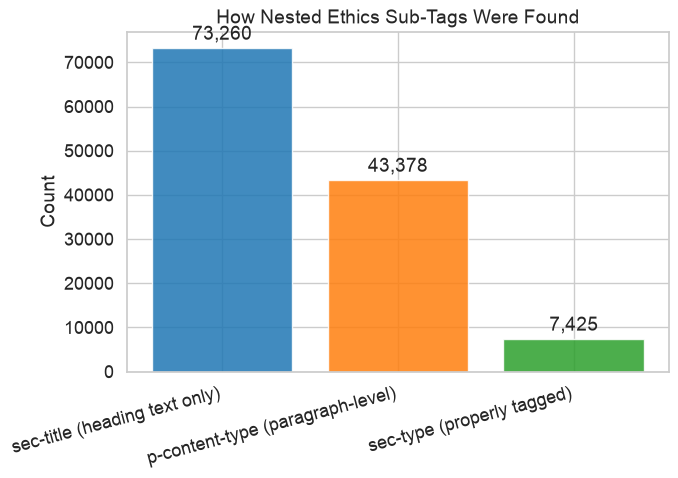

In [8]:
# ── 5.1 Sub-type tagging quality: how was each nested tag found? ────────────
sub_df = qdb("""
    SELECT est.source_attr, est.value, es.article_id
    FROM ethics_sub_type est
    JOIN ethics_statement es ON es.ethics_id = est.ethics_id
    JOIN article a           ON a.article_id = es.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

ATTR_LABELS = {'sec-type': 'sec-type (properly tagged)',
               'sec-title': 'sec-title (heading text only)',
               'p-content-type': 'p-content-type (paragraph-level)'}
ATTR_COLOURS = {'sec-type': '#2ca02c', 'sec-title': '#1f77b4', 'p-content-type': '#ff7f0e'}

attr_vc = sub_df['source_attr'].value_counts()
print(f"Total nested ethics sub-tags found: {len(sub_df):,}")
for attr, n in attr_vc.items():
    print(f"  {ATTR_LABELS.get(attr, attr):32}  {n:>7,}  ({n/len(sub_df)*100:4.1f}%)")

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar([ATTR_LABELS.get(a, a) for a in attr_vc.index], attr_vc.values,
              color=[ATTR_COLOURS.get(a, '#888') for a in attr_vc.index],
              alpha=0.85, edgecolor='white')
ax.bar_label(bars, fmt='{:,.0f}', padding=3)
ax.set_ylabel('Count'); ax.set_title('How Nested Ethics Sub-Tags Were Found')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth04b_subtype_tagging.png", **SAVEFIG_KWARGS)
plt.show()

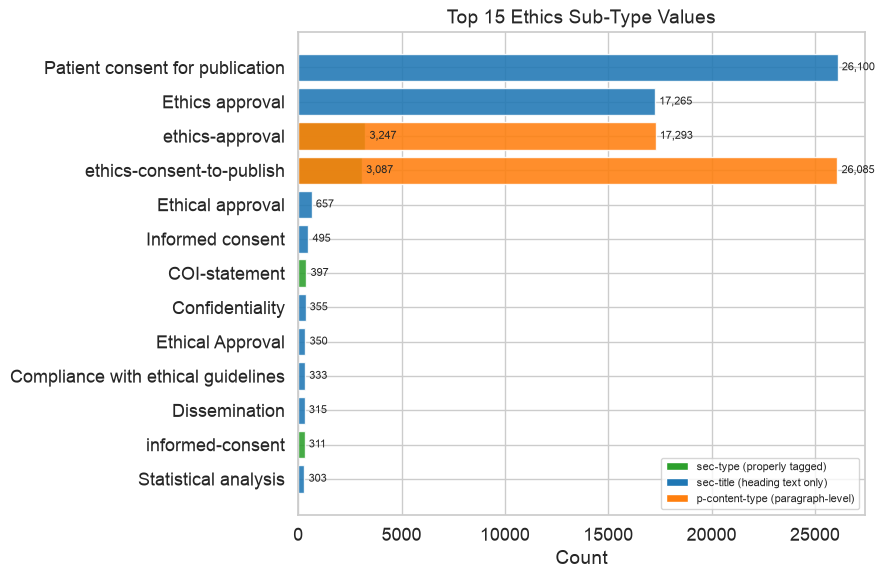

In [9]:
# ── 5.2 Top 15 sub-type values ───────────────────────────────────────────────
sub_top = (sub_df.groupby(['source_attr','value']).size()
           .reset_index(name='n').sort_values('n', ascending=False).head(15))
sub_top['label'] = sub_top['value'].str.slice(0, 45)

fig, ax = plt.subplots(figsize=(9, 6))
clrs = [ATTR_COLOURS.get(a, '#888') for a in sub_top['source_attr']]
bars = ax.barh(sub_top['label'][::-1], sub_top['n'][::-1], color=clrs[::-1],
               alpha=0.88, edgecolor='white')
ax.bar_label(bars, fmt='{:,.0f}', padding=3, fontsize=8)
ax.set_xlabel('Count'); ax.set_title('Top 15 Ethics Sub-Type Values')

from matplotlib.patches import Patch
legend_els = [Patch(fc=c, label=ATTR_LABELS[a]) for a, c in ATTR_COLOURS.items()]
ax.legend(handles=legend_els, fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth04c_subtype_top15.png", **SAVEFIG_KWARGS)
plt.show()

In [10]:
# ── 5.3 Of the properly-tagged sec-type values, how many match the 5 ────────
# JATS4R-suggested exact values vs. are publisher-specific variants?
JATS4R_SUB_VALUES = {'ethics-consent-to-publish', 'ethics-review-body', 'ethics-approval',
                      'ethics-approval-human', 'ethics-approval-animal'}

sectype_only = sub_df[sub_df['source_attr'] == 'sec-type'].copy()
sectype_only['is_recommended'] = sectype_only['value'].isin(JATS4R_SUB_VALUES)
n_rec = sectype_only['is_recommended'].sum()
n_tot = len(sectype_only)

print(f"Of {n_tot:,} properly-typed (sec-type) ethics sub-tags:")
print(f"  Matches one of the 5 JATS4R-suggested values : {n_rec:,}  ({n_rec/n_tot*100:.1f}%)")
print(f"  Publisher-specific variant                   : {n_tot-n_rec:,}  ({(n_tot-n_rec)/n_tot*100:.1f}%)")
print()
print("Usage of each suggested value (0 = never used in this corpus):")
for v in sorted(JATS4R_SUB_VALUES):
    n = (sectype_only['value'] == v).sum()
    print(f"  {v:28} {n:>6,}")

Of 7,425 properly-typed (sec-type) ethics sub-tags:
  Matches one of the 5 JATS4R-suggested values : 6,334  (85.3%)
  Publisher-specific variant                   : 1,091  (14.7%)

Usage of each suggested value (0 = never used in this corpus):
  ethics-approval               3,247
  ethics-approval-animal            0
  ethics-approval-human             0
  ethics-consent-to-publish     3,087
  ethics-review-body                0


---
## Section 6 -- Ethics Sub-type Signals

Eight binary signals classify *what kind* of ethical declaration is made:
IRB approval, informed consent, Helsinki compliance, human subjects,
animal subjects, approval waived, approval number cited, data anonymisation.
These map directly to the JATS4R suggested sub-values
(`ethics-approval-human`, `ethics-approval-animal`, `ethics-consent-to-publish`, etc.).


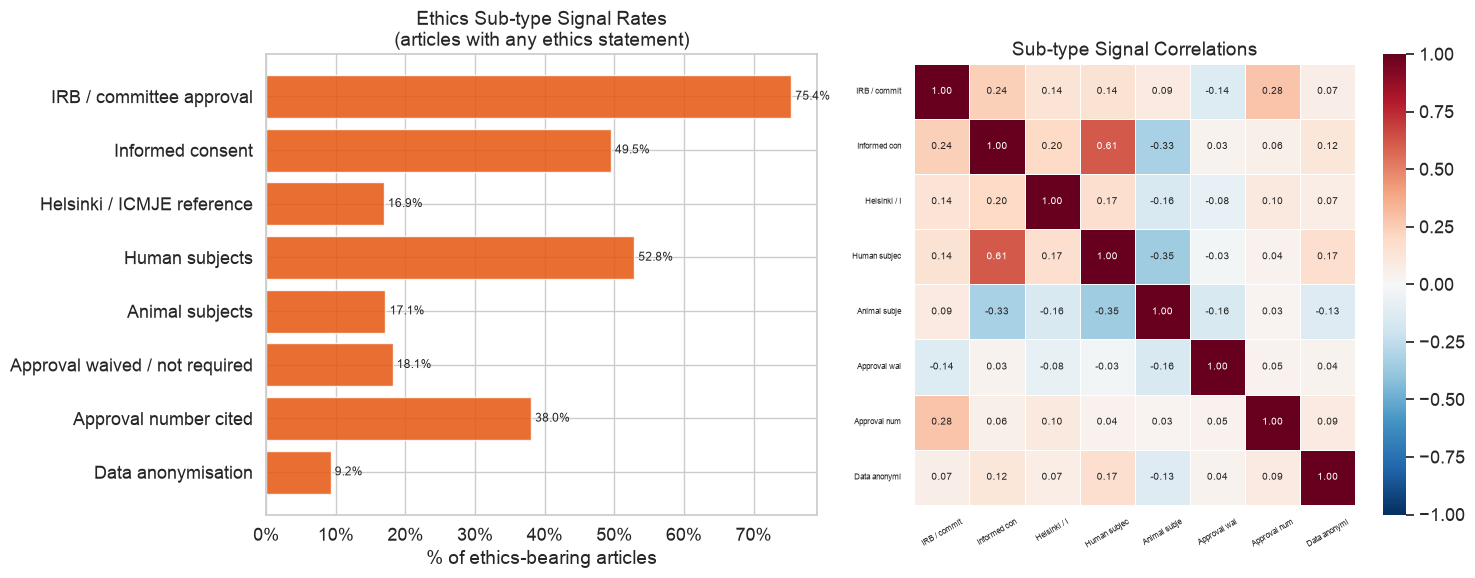

  IRB / committee approval              75.4%
  Informed consent                      49.5%
  Helsinki / ICMJE reference            16.9%
  Human subjects                        52.8%
  Animal subjects                       17.1%
  Approval waived / not required        18.1%
  Approval number cited                 38.0%
  Data anonymisation                     9.2%


In [11]:
ETH_SIGS = ['has_irb','has_consent','has_helsinki','has_human',
            'has_animal','has_waived','has_approval_num','has_data_anon']
SIG_LBL = {
    'has_irb':          'IRB / committee approval',
    'has_consent':      'Informed consent',
    'has_helsinki':     'Helsinki / ICMJE reference',
    'has_human':        'Human subjects',
    'has_animal':       'Animal subjects',
    'has_waived':       'Approval waived / not required',
    'has_approval_num': 'Approval number cited',
    'has_data_anon':    'Data anonymisation',
}

eth_df = df[df['has_ethics']].copy()
sig_rates = (eth_df[ETH_SIGS].mean() * 100).rename('rate')

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 1))

# Prevalence bar
ax = axes[0]
bars = ax.barh([SIG_LBL[s] for s in ETH_SIGS][::-1],
               [sig_rates[s] for s in ETH_SIGS][::-1],
               color='#e6550d', alpha=0.85, edgecolor='white')
ax.bar_label(bars, fmt='{:.1f}%', padding=3, fontsize=8.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('% of ethics-bearing articles')
ax.set_title('Ethics Sub-type Signal Rates\n(articles with any ethics statement)')

# Signal co-occurrence heatmap
ax = axes[1]
sig_df = eth_df[ETH_SIGS].copy()
sig_df.columns = [SIG_LBL[s][:18] for s in ETH_SIGS]
corr = sig_df.corr()
sns.heatmap(corr, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size':7},
            linewidths=0.4, square=True,
            xticklabels=[c[:12] for c in corr.columns],
            yticklabels=[c[:12] for c in corr.index])
ax.set_title('Sub-type Signal Correlations')
ax.tick_params(axis='x', labelsize=6, rotation=30)
ax.tick_params(axis='y', labelsize=6)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth05_signals.png", **SAVEFIG_KWARGS)
plt.show()

for s in ETH_SIGS:
    print(f'  {SIG_LBL[s]:35}  {sig_rates[s]:5.1f}%')


---
## Section 7 -- Ethics Presence vs Data Sharing

The central question: do articles with ethics statements share data at
higher rates, and do they receive higher data-sharing scores? This tests whether
open-science culture is monolithic (ethics + data sharing advance together)
or fragmented (they respond to independent drivers).


Ethics x DAS presence (chi-squared):
Has DAS       False    True 
Has ethics                  
False       3444186  2185331
True         418947   825712
Chi2=313632.3  df=1  p=0.00e+00  Cramer V=0.2136


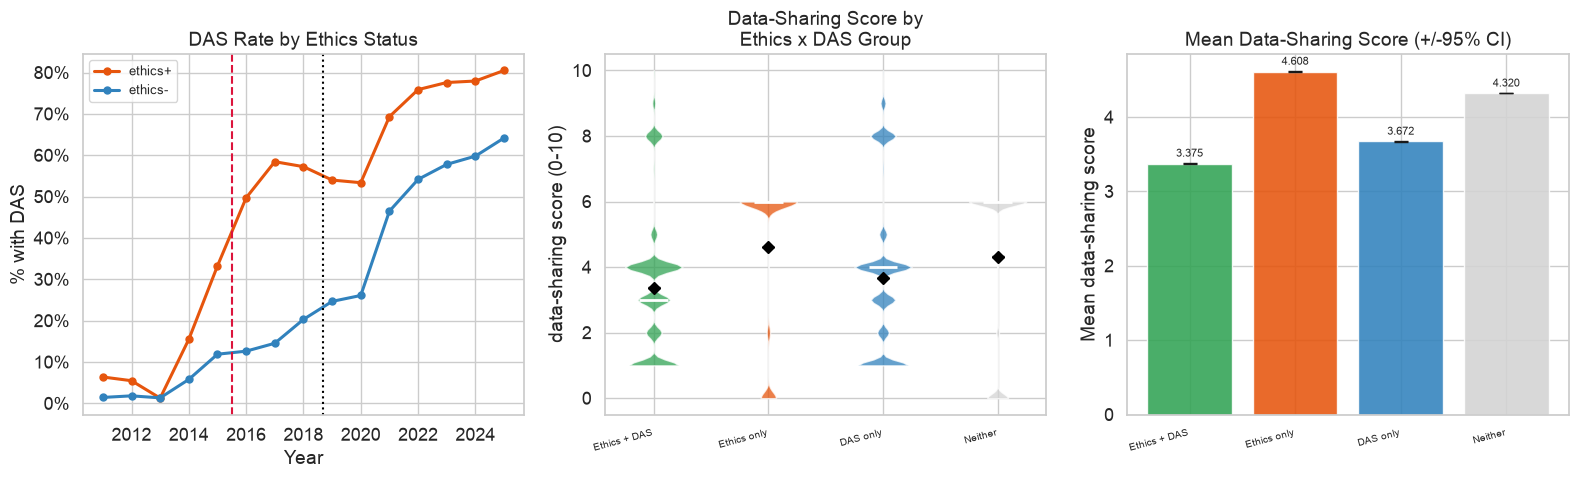


Mean data-sharing scores by group:
  Ethics + DAS       n= 825,712  mean=3.3746  med=3.0000
  Ethics only        n= 418,947  mean=4.6081  med=6.0000
  DAS only           n=2,185,331  mean=3.6719  med=4.0000
  Neither            n=3,444,186  mean=4.3198  med=6.0000


In [12]:
# Chi-squared test: ethics x DAS presence
ct = pd.crosstab(df['has_ethics'], df['has_das'],
                 rownames=['Has ethics'], colnames=['Has DAS'])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
V = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print('Ethics x DAS presence (chi-squared):')
print(ct)
print(f'Chi2={chi2:.1f}  df={dof}  p={p_chi:.2e}  Cramer V={V:.4f}')

# Year-stratified DAS rate
yr_das_eth = (
    df.groupby(['year','has_ethics'])['has_das']
    .mean().unstack()
    .rename(columns={True:'ethics+', False:'ethics-'}) * 100)

# data-sharing score by 2x2 group
g_masks = {
    'Ethics + DAS': df['has_ethics'] & df['has_das'],
    'Ethics only':  df['has_ethics'] & ~df['has_das'],
    'DAS only':     ~df['has_ethics'] & df['has_das'],
    'Neither':      ~df['has_ethics'] & ~df['has_das'],
}
g_scores = {k: df[m]['data_sharing_score'].dropna() for k, m in g_masks.items()}

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H))

# DAS rate over time by ethics status
ax = axes[0]
for col, clr in [('ethics+','#e6550d'), ('ethics-','#3182bd')]:
    if col in yr_das_eth.columns:
        ax.plot(yr_das_eth.index, yr_das_eth[col],
                lw=2.2, marker='o', ms=5, color=clr, label=col)
ax.axvline(2015.5,  color='crimson', lw=1.5, ls='--')
ax.axvline(2018.67, color='black',   lw=1.5, ls=':')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Year'); ax.set_ylabel('% with DAS')
ax.set_title('DAS Rate by Ethics Status')
ax.legend(fontsize=9)

# Violin: data-sharing score by group
ax = axes[1]
clrs4 = ['#31a354','#e6550d','#3182bd','#d3d3d3']
valid = [(k, v) for k, v in g_scores.items() if len(v) >= 2]
if valid:
    parts = ax.violinplot([v.values for _, v in valid],
                          showmedians=True, showextrema=False)
    for pc, clr in zip(parts['bodies'], clrs4):
        pc.set_facecolor(clr); pc.set_alpha(0.75)
    parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
    for i, (_, v) in enumerate(valid):
        ax.errorbar(i+1, v.mean(), yerr=1.96*v.std()/len(v)**0.5,
                    fmt='D', color='black', ms=6, capsize=4, zorder=5)
    ax.set_xticks(range(1, len(valid)+1))
    ax.set_xticklabels([k for k,_ in valid], rotation=15, ha='right', fontsize=7.5)
ax.set_ylabel('data-sharing score (0-10)')
ax.set_title('Data-Sharing Score by\nEthics x DAS Group')

# Mean Score bar
ax = axes[2]
means = [(k, v.mean(), 1.96*v.std()/max(len(v),2)**0.5)
         for k, v in g_scores.items() if len(v) >= 2]
bars = ax.bar(range(len(means)),
              [m for _,m,_ in means],
              yerr=[e for _,_,e in means],
              color=clrs4[:len(means)], alpha=0.88, edgecolor='white', capsize=5)
ax.bar_label(bars, fmt='{:.3f}', padding=3, fontsize=8)
ax.set_xticks(range(len(means)))
ax.set_xticklabels([k for k,_,_ in means], rotation=15, ha='right', fontsize=7.5)
ax.set_ylabel('Mean data-sharing score')
ax.set_title('Mean Data-Sharing Score (+/-95% CI)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth06_fair_by_group.png", **SAVEFIG_KWARGS)
plt.show()

print('\nMean data-sharing scores by group:')
for k, v in g_scores.items():
    if len(v) >= 2:
        print(f'  {k:17}  n={len(v):>8,}  mean={v.mean():.4f}  med={v.median():.4f}')


---
## Section 8 -- Ethics Sub-type vs Data Sharing Behaviour

Human-subjects studies have patient-privacy constraints that often
*prevent* open data deposit. Animal studies have no such constraints.
IRB-approved studies that cite a specific approval number signal mature
oversight infrastructure -- possibly co-occurring with stricter data mandates.
Waiver statements may indicate low-data-volume studies less likely to have
a DAS at all. We test each sub-type's independent effect on DAS presence
and data-sharing score using Mann-Whitney U.


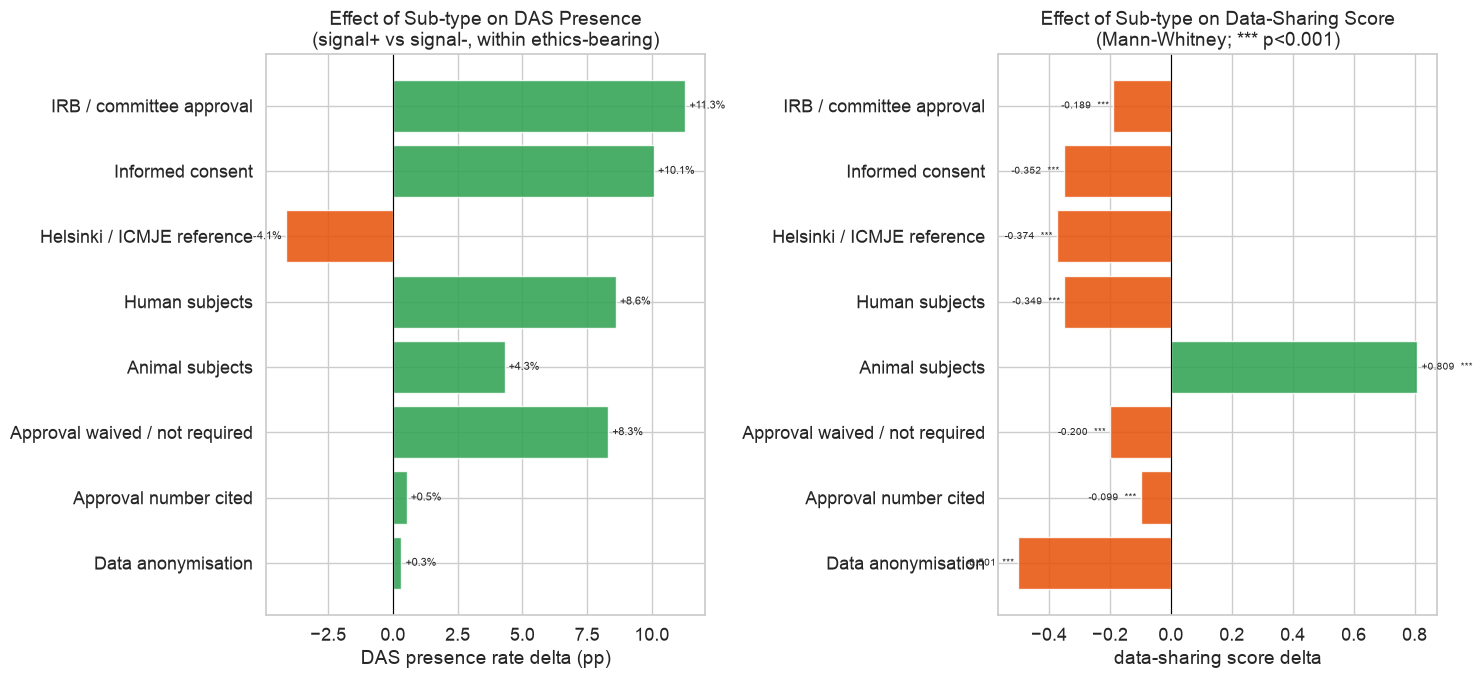

                        signal  n_pos  das_pos  das_neg  das_delta  score_pos  score_neg  score_delta sig
      IRB / committee approval 938541   69.117   57.827     11.290      3.743      3.932       -0.189 ***
              Informed consent 616142   71.428   61.353     10.075      3.612      3.964       -0.352 ***
    Helsinki / ICMJE reference 210187   62.914   67.037     -4.123      3.479      3.853       -0.374 ***
                Human subjects 657770   70.399   61.792      8.607      3.625      3.974       -0.349 ***
               Animal subjects 213273   69.911   65.602      4.309      4.461      3.651        0.809 ***
Approval waived / not required 225899   73.143   64.832      8.311      3.626      3.826       -0.200 ***
         Approval number cited 473338   66.667   66.140      0.526      3.728      3.828       -0.099 ***
            Data anonymisation 115096   66.640   66.310      0.330      3.336      3.836       -0.501 ***


In [13]:
rows = []
for sig in ETH_SIGS:
    pos = eth_df[eth_df[sig] == 1]
    neg = eth_df[eth_df[sig] == 0]
    das_pos = pos['has_das'].mean() * 100
    das_neg = neg['has_das'].mean() * 100
    a = pos['data_sharing_score'].dropna()
    b = neg['data_sharing_score'].dropna()
    if len(a) >= 2 and len(b) >= 2:
        u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        r_e = u / (len(a) * len(b))
        slbl = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
    else:
        p = r_e = float('nan'); slbl = '-'
    rows.append({
        'signal': SIG_LBL[sig], 'n_pos': len(pos),
        'das_pos': das_pos, 'das_neg': das_neg, 'das_delta': das_pos - das_neg,
        'score_pos': a.mean() if len(a) else float('nan'),
        'score_neg': b.mean() if len(b) else float('nan'),
        'score_delta': (a.mean() - b.mean()) if (len(a) and len(b)) else float('nan'),
        'p': p, 'r': r_e, 'sig': slbl,
    })
df_sig = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 2))

for ax, col, xlabel, title in [
        (axes[0], 'das_delta',  'DAS presence rate delta (pp)',
         'Effect of Sub-type on DAS Presence\n(signal+ vs signal-, within ethics-bearing)'),
        (axes[1], 'score_delta', 'data-sharing score delta',
         'Effect of Sub-type on Data-Sharing Score\n(Mann-Whitney; *** p<0.001)')
]:
    clrs = ['#31a354' if d >= 0 else '#e6550d'
            for d in df_sig[col]]
    bars = ax.barh(df_sig['signal'][::-1], df_sig[col][::-1],
                   color=clrs[::-1], alpha=0.88, edgecolor='white')
    if col == 'score_delta':
        ax.bar_label(bars,
                     labels=[f'{d:+.3f}  {s}'
                             for d, s in zip(df_sig[col][::-1],
                                             df_sig['sig'][::-1])],
                     padding=3, fontsize=7.5)
    else:
        ax.bar_label(bars, fmt='{:+.1f}%', padding=3, fontsize=8)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel(xlabel); ax.set_title(title)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth07_subtype_das.png", **SAVEFIG_KWARGS)
plt.show()

print(df_sig[['signal','n_pos','das_pos','das_neg','das_delta',
              'score_pos','score_neg','score_delta','sig']].round(3).to_string(index=False))


---
## Section 9 -- Co-evolution of Ethics Statements and DAS

Ethics statement adoption and DAS adoption are driven by overlapping
pressures: funder mandates, journal policies, and community norms.
This section tests whether the two practices move together over time,
and whether the conditional DAS rate (given an ethics statement exists)
has increased post-recommendation.


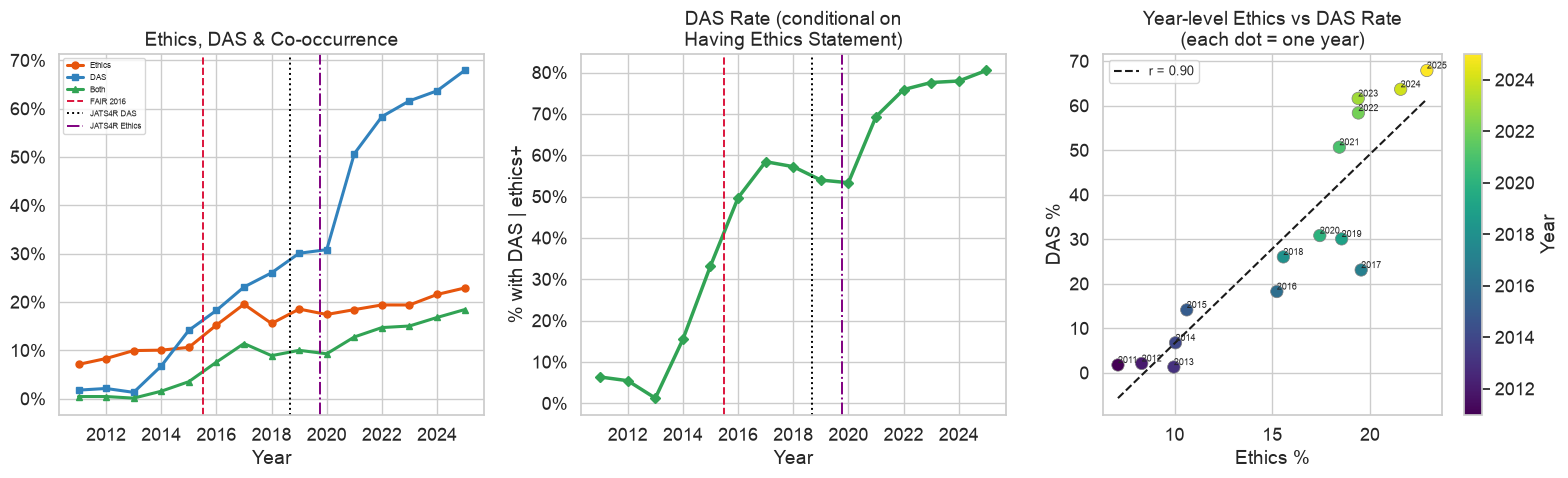

In [14]:
yr_co = df.groupby('year').agg(
    n_total=('article_id','count'),
    n_eth  =('has_ethics','sum'),
    n_das  =('has_das','sum'),
    n_both =('both','sum'),
).reset_index()
yr_co['pct_eth']      = yr_co['n_eth']  / yr_co['n_total'] * 100
yr_co['pct_das']      = yr_co['n_das']  / yr_co['n_total'] * 100
yr_co['pct_both']     = yr_co['n_both'] / yr_co['n_total'] * 100
yr_co['das_cond_eth'] = yr_co['n_both'] / yr_co['n_eth'].clip(1) * 100

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H))

ax = axes[0]
for col, clr, mrk, lbl in [
        ('pct_eth','#e6550d','o','Ethics'),
        ('pct_das','#3182bd','s','DAS'),
        ('pct_both','#31a354','^','Both')]:
    ax.plot(yr_co['year'], yr_co[col], lw=2.2, marker=mrk, ms=5, color=clr, label=lbl)
for xv,clr,ls,lbl in [(2015.5,'crimson','--','FAIR 2016'),
                       (2018.67,'black',':','JATS4R DAS'),
                       (2019.75,'purple','-.','JATS4R Ethics')]:
    ax.axvline(xv, color=clr, lw=1.4, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Ethics, DAS & Co-occurrence'); ax.legend(fontsize=6); ax.set_xlabel('Year')

ax = axes[1]
ax.plot(yr_co['year'], yr_co['das_cond_eth'],
        lw=2.5, marker='D', ms=5, color='#31a354')
for xv,clr,ls in [(2015.5,'crimson','--'),(2018.67,'black',':'),(2019.75,'purple','-.' )]:
    ax.axvline(xv, color=clr, lw=1.4, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('DAS Rate (conditional on\nHaving Ethics Statement)')
ax.set_xlabel('Year'); ax.set_ylabel('% with DAS | ethics+')

ax = axes[2]
sc = ax.scatter(yr_co['pct_eth'], yr_co['pct_das'],
                c=yr_co['year'], cmap='viridis', s=80, edgecolors='grey', lw=0.5)
sl, ic, r, _, _ = stats.linregress(yr_co['pct_eth'], yr_co['pct_das'])
xs = np.linspace(yr_co['pct_eth'].min(), yr_co['pct_eth'].max(), 50)
ax.plot(xs, ic + sl*xs, 'k--', lw=1.5, label=f'r = {r:.2f}')
for _, row in yr_co.iterrows():
    ax.annotate(str(int(row['year'])),
                (row['pct_eth'], row['pct_das']),
                fontsize=6.5, ha='left', va='bottom')
plt.colorbar(sc, ax=ax, label='Year')
ax.set_xlabel('Ethics %'); ax.set_ylabel('DAS %')
ax.set_title('Year-level Ethics vs DAS Rate\n(each dot = one year)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth08_coevolution.png", **SAVEFIG_KWARGS)
plt.show()


---
## Section 10 -- JATS4R Ethics Compliance vs DAS Compliance

If XML production quality is a publisher-level property then journals
that correctly tag `sec-type="ethics-statement"` should also correctly
tag `sec-type="data-availability"`. We test this at article level
and at journal level.


Ethics compliance x DAS compliance (articles with both):
DAS compliant      False   True 
Ethics compliant                
False             311698  383952
True                 562  129500
Chi2=91751.7  p=0.00e+00  Cramer V=0.3333


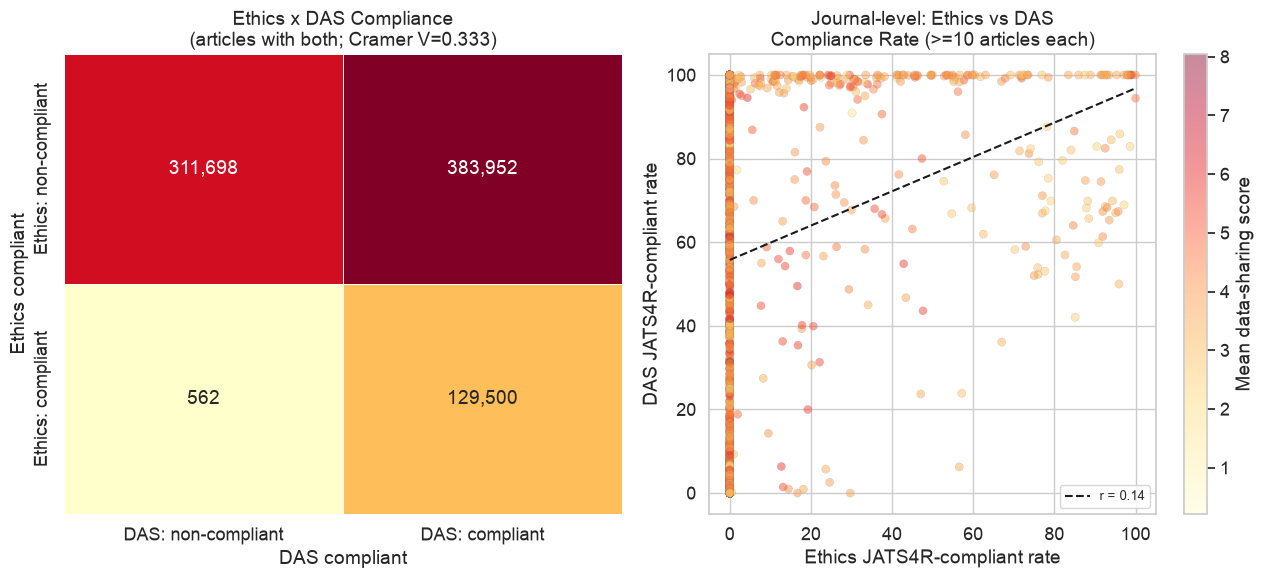

In [15]:
both_df = df[df['has_ethics'] & df['has_das']].copy()
both_df['eth_comp'] = both_df['eth_tier'] == 'compliant'
both_df['das_comp'] = both_df['das_tier'] == 'compliant'

ct2 = pd.crosstab(both_df['eth_comp'], both_df['das_comp'],
                  rownames=['Ethics compliant'], colnames=['DAS compliant'])
chi2c, pc, _, _ = stats.chi2_contingency(ct2)
Vc = np.sqrt(chi2c / (ct2.values.sum() * (min(ct2.shape) - 1)))
print('Ethics compliance x DAS compliance (articles with both):')
print(ct2)
print(f'Chi2={chi2c:.1f}  p={pc:.2e}  Cramer V={Vc:.4f}')

# Journal-level
j_agg = df.groupby('journal_id').agg(
    n_eth    =('has_ethics','sum'),
    n_das    =('has_das','sum'),
    eth_comp =('eth_tier', lambda x: (x=='compliant').sum()),
    das_comp =('das_tier', lambda x: (x=='compliant').sum()),
    mean_score=('data_sharing_score','mean'),
).reset_index()
j_agg['pct_eth_comp'] = j_agg['eth_comp'] / j_agg['n_eth'].clip(1) * 100
j_agg['pct_das_comp'] = j_agg['das_comp'] / j_agg['n_das'].clip(1) * 100
j30 = j_agg[(j_agg['n_eth'] >= 10) & (j_agg['n_das'] >= 10)]

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H + 1))

ax = axes[0]
sns.heatmap(ct2, annot=True, fmt=',d', cmap='YlOrRd', ax=ax,
            linewidths=0.4, cbar=False,
            xticklabels=['DAS: non-compliant','DAS: compliant'],
            yticklabels=['Ethics: non-compliant','Ethics: compliant'])
ax.set_title(f'Ethics x DAS Compliance\n(articles with both; Cramer V={Vc:.3f})')

ax = axes[1]
sc = ax.scatter(j30['pct_eth_comp'], j30['pct_das_comp'],
                alpha=0.45, s=35, c=j30['mean_score'],
                cmap='YlOrRd', edgecolors='grey', lw=0.2)
if len(j30) >= 5:
    sl, ic, r, _, _ = stats.linregress(
        j30['pct_eth_comp'].fillna(0), j30['pct_das_comp'].fillna(0))
    xs = np.linspace(0, 100, 50)
    ax.plot(xs, ic + sl*xs, 'k--', lw=1.5, label=f'r = {r:.2f}')
    ax.legend(fontsize=9)
plt.colorbar(sc, ax=ax, label='Mean data-sharing score')
ax.set_xlabel('Ethics JATS4R-compliant rate')
ax.set_ylabel('DAS JATS4R-compliant rate')
ax.set_title('Journal-level: Ethics vs DAS\nCompliance Rate (>=10 articles each)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth09_jats4r_xcomp.png", **SAVEFIG_KWARGS)
plt.show()


---
## Section 11 -- Ethics Statement Verbosity and Text Content

Longer ethics statements with cited approval numbers signal more mature
institutional practice. We test whether verbosity predicts data sharing.


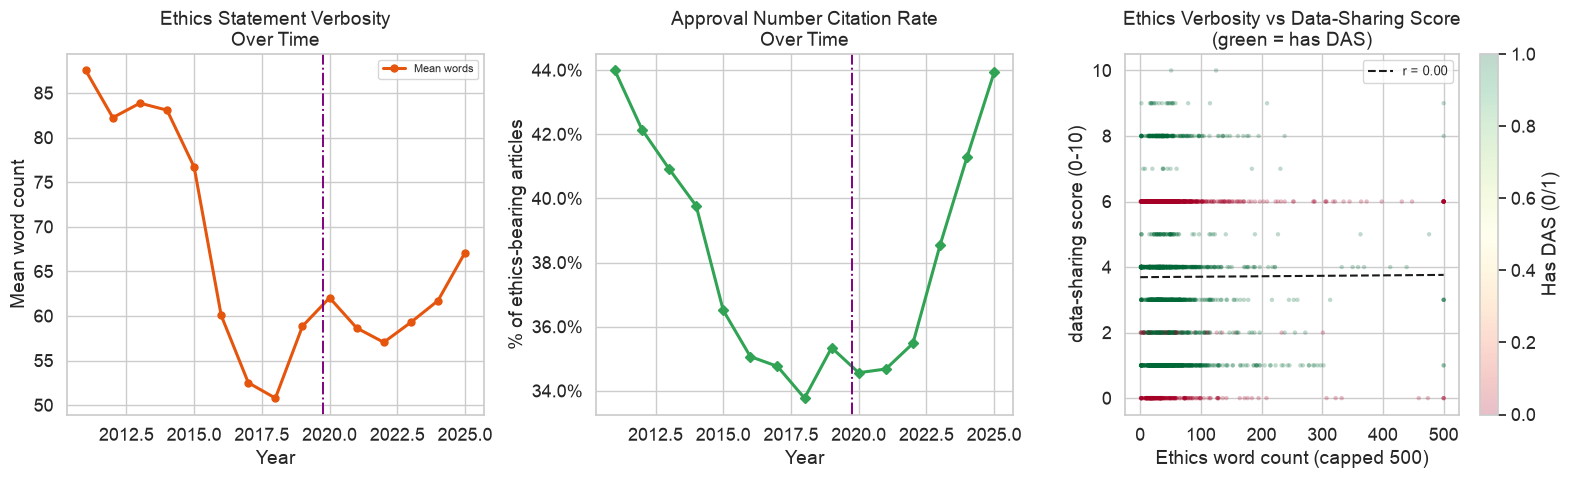

In [16]:
yr_text = eth_df.groupby('year').agg(
    mean_words   =('eth_words','mean'),
    pct_appr_num =('has_approval_num','mean'),
    pct_das      =('has_das','mean'),
).reset_index()
yr_text['pct_appr_num'] *= 100
yr_text['pct_das']      *= 100

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H))

ax = axes[0]
ax.plot(yr_text['year'], yr_text['mean_words'],
        lw=2.2, marker='o', ms=5, color='#e6550d', label='Mean words')
ax.axvline(2019.75, color='purple', lw=1.4, ls='-.')
ax.set_ylabel('Mean word count')
ax.set_title('Ethics Statement Verbosity\nOver Time')
ax.set_xlabel('Year'); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(yr_text['year'], yr_text['pct_appr_num'],
        lw=2.2, marker='D', ms=5, color='#31a354')
ax.axvline(2019.75, color='purple', lw=1.4, ls='-.')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Approval Number Citation Rate\nOver Time')
ax.set_xlabel('Year'); ax.set_ylabel('% of ethics-bearing articles')

ax = axes[2]
sample = eth_df.dropna(subset=['data_sharing_score']).sample(
    min(3000, len(eth_df)), random_state=42)
sc = ax.scatter(sample['eth_words'].clip(0, 500), sample['data_sharing_score'],
                alpha=0.25, s=10, c=sample['has_das'].astype(int),
                cmap='RdYlGn', edgecolors='none')
plt.colorbar(sc, ax=ax, label='Has DAS (0/1)')
if len(sample) >= 5:
    sl, ic, r, _, _ = stats.linregress(
        sample['eth_words'].clip(0, 500), sample['data_sharing_score'])
    xs = np.linspace(0, 500, 50)
    ax.plot(xs, ic + sl*xs, 'k--', lw=1.5, label=f'r = {r:.2f}')
    ax.legend(fontsize=9)
ax.set_xlabel('Ethics word count (capped 500)')
ax.set_ylabel('data-sharing score (0-10)')
ax.set_title('Ethics Verbosity vs Data-Sharing Score\n(green = has DAS)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth10_text.png", **SAVEFIG_KWARGS)
plt.show()


---
## Section 12 -- Publisher League Table

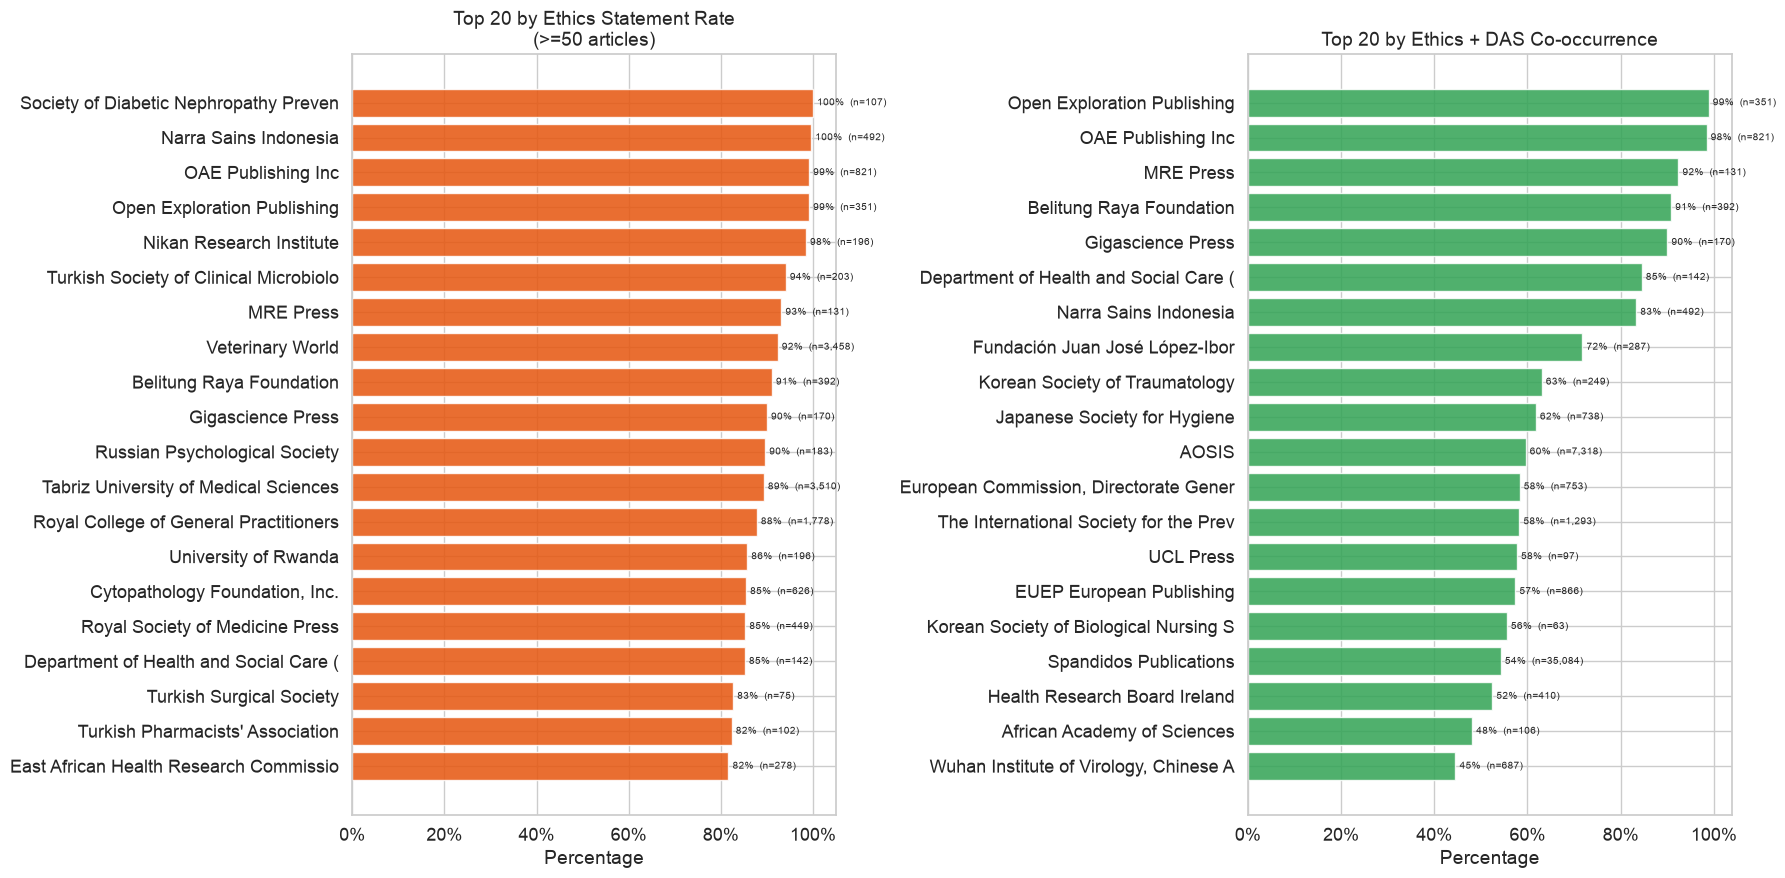

In [17]:
pub = df.groupby('publisher').agg(
    n_total  =('article_id','count'),
    n_eth    =('has_ethics','sum'),
    n_das    =('has_das','sum'),
    n_both   =('both','sum'),
    eth_comp =('eth_tier', lambda x: (x=='compliant').sum()),
    mean_score=('data_sharing_score','mean'),
).reset_index()
pub['pct_eth']      = pub['n_eth']  / pub['n_total']      * 100
pub['pct_das']      = pub['n_das']  / pub['n_total']      * 100
pub['pct_both']     = pub['n_both'] / pub['n_total']      * 100
pub['pct_eth_comp'] = pub['eth_comp'] / pub['n_eth'].clip(1) * 100
pub50 = pub[pub['n_total'] >= 50].copy()
pub50['short'] = pub50['publisher'].apply(
    lambda p: str(p or '(unknown)')[:38])

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 5, FIG_H + 4))

for ax, col, clr, title in [
        (axes[0], 'pct_eth',  '#e6550d',
         'Top 20 by Ethics Statement Rate\n(>=50 articles)'),
        (axes[1], 'pct_both', '#31a354',
         'Top 20 by Ethics + DAS Co-occurrence')]:
    sub = pub50.nlargest(20, col)
    bars = ax.barh(sub['short'][::-1], sub[col][::-1],
                   color=clr, alpha=0.85, edgecolor='white')
    ax.bar_label(bars,
                 labels=[f'{v:.0f}%  (n={int(n):,})'
                         for v, n in zip(sub[col][::-1],
                                         sub['n_total'][::-1])],
                 padding=3, fontsize=7.5)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_xlabel('Percentage'); ax.set_title(title)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth11_publisher.png", **SAVEFIG_KWARGS)
plt.show()


---
## Section 13 -- Discipline Breakdown  *(Stage 6)*

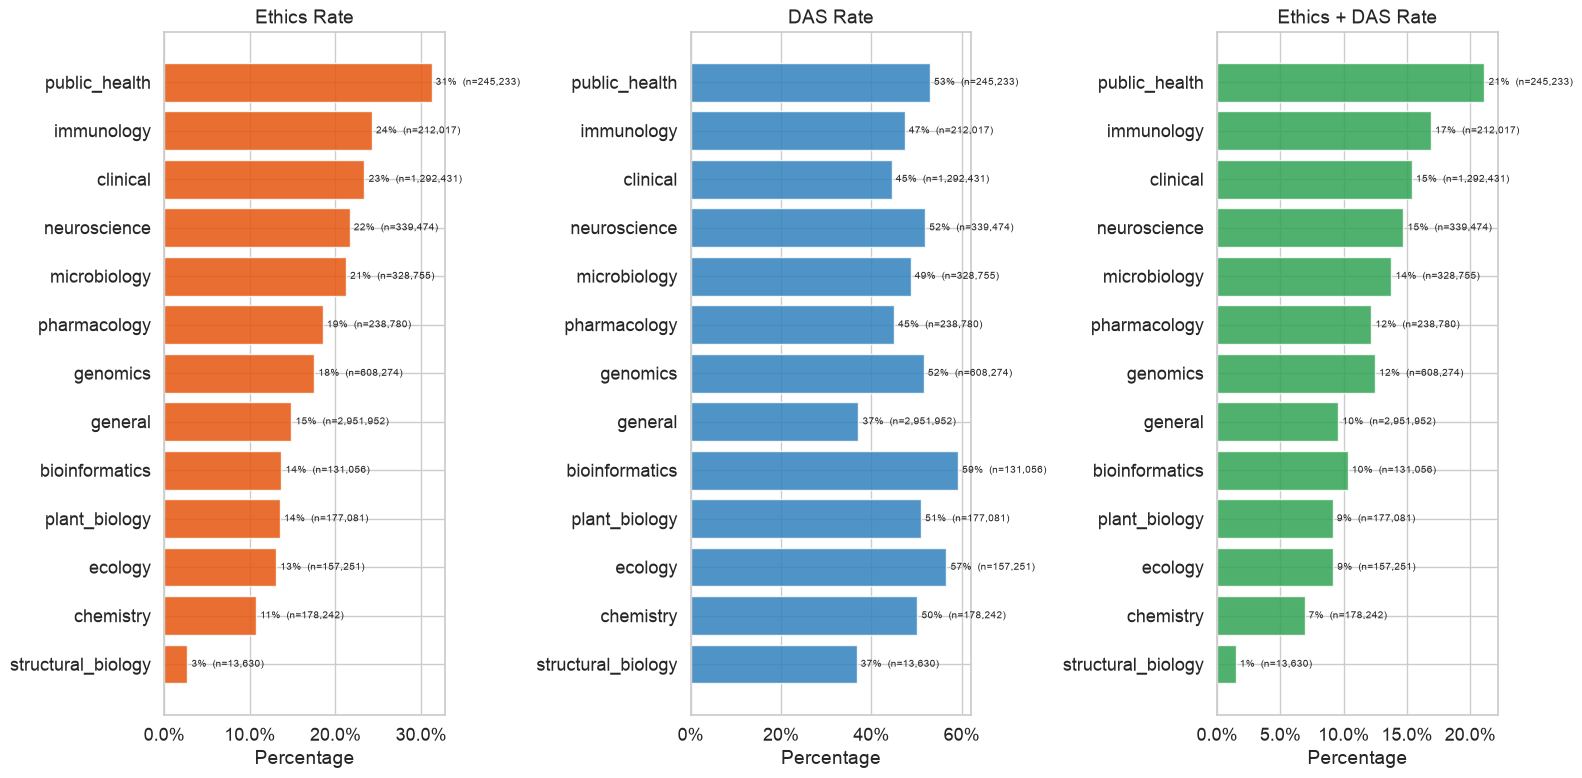

In [18]:
if not HAS_DISC:
    print('Skipped -- discipline data not available in this database.')
else:
    df_disc = qdb("""
        SELECT a.article_id, ad.discipline
        FROM article a
        JOIN article_discipline ad ON ad.article_id = a.article_id
        WHERE a.year BETWEEN 2011 AND 2025
    """)
    df_disc = df_disc.merge(
        df[['article_id','has_ethics','has_das','both','data_sharing_score']],
        on='article_id')
    dagg = df_disc.groupby('discipline').agg(
        n_total  =('article_id','count'),
        n_eth    =('has_ethics','sum'),
        n_das    =('has_das','sum'),
        n_both   =('both','sum'),
        mean_score=('data_sharing_score','mean'),
    ).reset_index()
    dagg['pct_eth']  = dagg['n_eth']  / dagg['n_total'] * 100
    dagg['pct_das']  = dagg['n_das']  / dagg['n_total'] * 100
    dagg['pct_both'] = dagg['n_both'] / dagg['n_total'] * 100
    dagg = dagg.sort_values('pct_eth', ascending=False)

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H + 3))
    for ax, col, clr, title in [
            (axes[0],'pct_eth', '#e6550d','Ethics Rate'),
            (axes[1],'pct_das', '#3182bd','DAS Rate'),
            (axes[2],'pct_both','#31a354','Ethics + DAS Rate')]:
        bars = ax.barh(dagg['discipline'][::-1], dagg[col][::-1],
                       color=clr, alpha=0.85, edgecolor='white')
        ax.bar_label(bars,
                     labels=[f'{v:.0f}%  (n={int(n):,})'
                             for v,n in zip(dagg[col][::-1],
                                            dagg['n_total'][::-1])],
                     padding=3, fontsize=7.5)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter())
        ax.set_xlabel('Percentage'); ax.set_title(title)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_eth12_discipline.png", **SAVEFIG_KWARGS)
    plt.show()


---
## Section 14 -- Four-Period Analysis, Statistics, and Exports

Four-period summary:
                   Period  Articles  Ethics pct  DAS pct  Both pct  Eth JATS4R pct  Mean Score
       Pre-FAIR (2011-15)    922067         9.6      6.3       1.5             0.0       4.507
         FAIR year (2016)    277445        15.2     18.3       7.6             0.0       4.433
Post-FAIR/pre-rec (17-18)    667672        17.5     24.7      10.1             0.0       4.358
       Post-rec (2019-24)   5006992        19.9     54.7      14.4            14.2       3.859


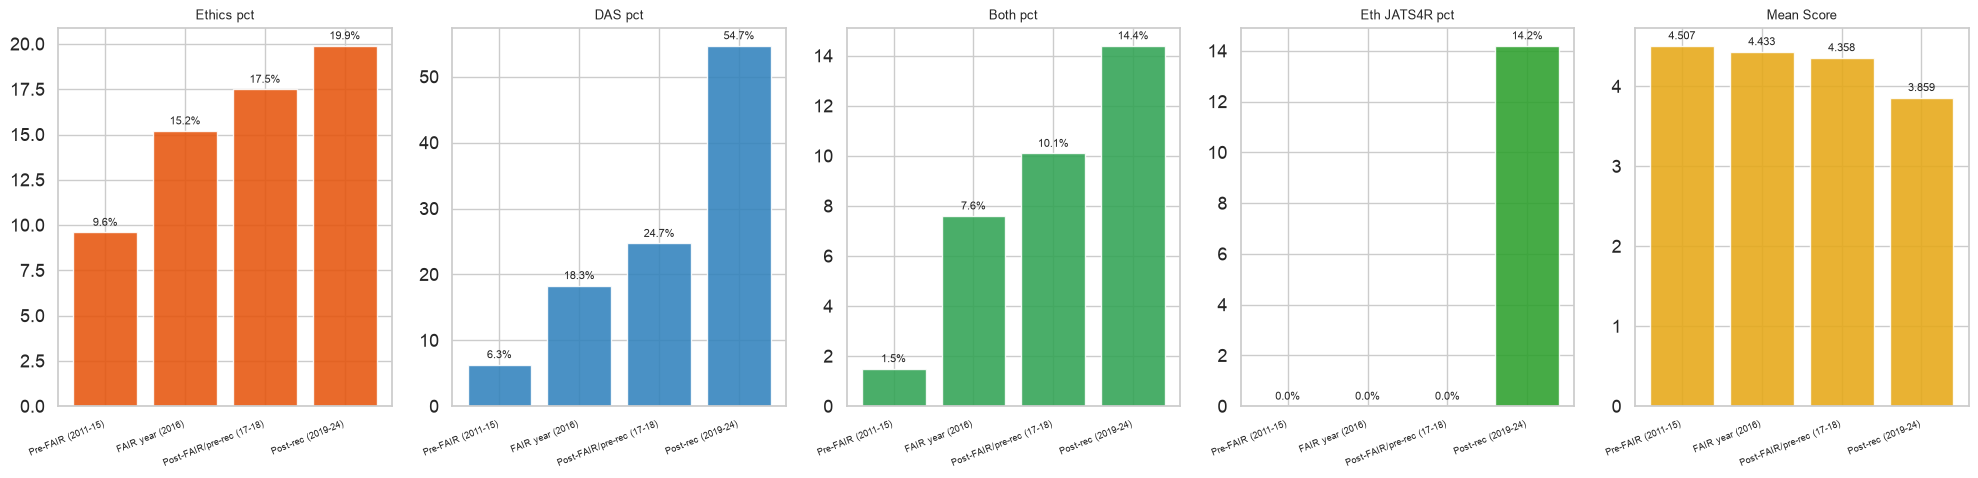

In [19]:
PERIODS = [
    ('Pre-FAIR (2011-15)',         df['year'] < 2016),
    ('FAIR year (2016)',           df['year'] == 2016),
    ('Post-FAIR/pre-rec (17-18)', df['year'].between(2017, 2018)),
    ('Post-rec (2019-24)',         df['year'] > 2018),
]
rows = []
for label, mask in PERIODS:
    sub = df[mask]
    if len(sub) == 0: continue
    ne = int(sub['has_ethics'].sum())
    nd = int(sub['has_das'].sum())
    nb = int(sub['both'].sum())
    nec = int((sub['eth_tier'] == 'compliant').sum())
    rows.append({
        'Period': label,
        'Articles': len(sub),
        'Ethics pct': round(ne / len(sub) * 100, 1),
        'DAS pct':    round(nd / len(sub) * 100, 1),
        'Both pct':   round(nb / len(sub) * 100, 1),
        'Eth JATS4R pct': round(nec / max(ne,1) * 100, 1),
        'Mean Score': round(sub['data_sharing_score'].mean(), 3),
    })
df_per = pd.DataFrame(rows)
print('Four-period summary:')
print(df_per.to_string(index=False))

fig, axes = plt.subplots(1, 5, figsize=(FIG_W + 7, FIG_H))
metrics = [
    ('Ethics pct',       '#e6550d'),
    ('DAS pct',          '#3182bd'),
    ('Both pct',         '#31a354'),
    ('Eth JATS4R pct',   '#2ca02c'),
    ('Mean Score',        '#e6a817'),
]
for ax, (col, clr) in zip(axes, metrics):
    bars = ax.bar(range(len(df_per)), df_per[col],
                  color=clr, alpha=0.88, edgecolor='white')
    fmt = '{:.1f}%' if 'pct' in col.lower() else '{:.3f}'
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=8)
    ax.set_xticks(range(len(df_per)))
    ax.set_xticklabels(df_per['Period'], rotation=22, ha='right', fontsize=6.5)
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_eth13_periods.png", **SAVEFIG_KWARGS)
plt.show()


In [20]:
# ── Statistical summary ──────────────────────────────────────────────────────
print('=' * 72)
print('ETHICS STATEMENTS AND DATA SHARING -- STATISTICAL SUMMARY')
print('=' * 72)

n_tot = len(df)
n_eth = int(df['has_ethics'].sum())
n_das = int(df['has_das'].sum())
n_both= int(df['both'].sum())
n_ec  = int((df['eth_tier'] == 'compliant').sum())

das_eth  = df[ df['has_ethics']]['has_das'].mean() * 100
das_neth = df[~df['has_ethics']]['has_das'].mean() * 100

sc_eth_das  = df[ df['has_ethics'] &  df['has_das']]['data_sharing_score'].dropna()
sc_das_only = df[~df['has_ethics'] &  df['has_das']]['data_sharing_score'].dropna()
sc_eth_only = df[ df['has_ethics'] & ~df['has_das']]['data_sharing_score'].dropna()
sc_neither  = df[~df['has_ethics'] & ~df['has_das']]['data_sharing_score'].dropna()

lines = [
    f'  Total articles (2011-2025)        : {n_tot:>9,}',
    f'  With ethics statement             : {n_eth:>9,}  ({n_eth/n_tot*100:.1f}%)',
    f'  With DAS                          : {n_das:>9,}  ({n_das/n_tot*100:.1f}%)',
    f'  With both                         : {n_both:>9,}  ({n_both/n_tot*100:.1f}%)',
    f'  Ethics JATS4R-compliant           : {n_ec:>9,}  ({n_ec/max(n_eth,1)*100:.1f}% of ethics)',
    '',
    f'  DAS rate | ethics+                : {das_eth:>8.1f}%',
    f'  DAS rate | ethics-                : {das_neth:>8.1f}%',
    f'  Uplift from ethics statement      : {das_eth-das_neth:>+8.1f} pp',
]
for ln in lines: print(ln)

print()
for grp, sc in [('Ethics+DAS', sc_eth_das), ('Ethics only', sc_eth_only),
                ('DAS only',   sc_das_only), ('Neither',    sc_neither)]:
    if len(sc) >= 2:
        print(f'  FAIR {grp:15} n={len(sc):>8,} mean={sc.mean():.4f} med={sc.median():.4f}')

if len(sc_eth_das) >= 2 and len(sc_das_only) >= 2:
    u, p = stats.mannwhitneyu(sc_eth_das, sc_das_only, alternative='two-sided')
    r_e  = u / (len(sc_eth_das) * len(sc_das_only))
    slbl = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
    d = sc_eth_das.mean() - sc_das_only.mean()
    print(f'  MW Ethics+DAS vs DAS-only: delta={d:+.4f} p={p:.2e} r={r_e:.4f} {slbl}')


ETHICS STATEMENTS AND DATA SHARING -- STATISTICAL SUMMARY


  Total articles (2011-2025)        : 6,874,176
  With ethics statement             : 1,244,659  (18.1%)
  With DAS                          : 3,011,043  (43.8%)
  With both                         :   825,712  (12.0%)
  Ethics JATS4R-compliant           :   141,400  (11.4% of ethics)

  DAS rate | ethics+                :     66.3%
  DAS rate | ethics-                :     38.8%
  Uplift from ethics statement      :    +27.5 pp

  FAIR Ethics+DAS      n= 825,712 mean=3.3746 med=3.0000
  FAIR Ethics only     n= 418,947 mean=4.6081 med=6.0000
  FAIR DAS only        n=2,185,331 mean=3.6719 med=4.0000
  FAIR Neither         n=3,444,186 mean=4.3198 med=6.0000


  MW Ethics+DAS vs DAS-only: delta=-0.2972 p=0.00e+00 r=0.4700 ***


In [21]:
# ── Exports ─────────────────────────────────────────────────────────────────
export_dir = Path('../results/fair_ethics_exports')
export_dir.mkdir(parents=True, exist_ok=True)

exports = {
    'article_ethics.csv': df[['article_id','year','eth_source','eth_tier',
                               'has_irb','has_consent','has_helsinki',
                               'has_human','has_animal','has_waived',
                               'has_approval_num','has_data_anon',
                               'eth_words','eth_sents',
                               'has_das','das_tier','data_sharing_score']],
    'subtype_effects.csv':     df_sig,
    'publisher_ethics.csv':    pub50[['publisher','n_total','pct_eth',
                                       'pct_das','pct_both','mean_score']],
    'four_period_ethics.csv':  df_per,
    'ethics_sectype_zoo.csv':  st_eth,
    'coevolution_by_year.csv': yr_co,
}
for fname, df_e in exports.items():
    if len(df_e) == 0:
        print(f'  Skipped (empty): {fname}')
        continue
    df_e.to_csv(export_dir / fname, index=False)
    print(f'  Saved {fname}  ({len(df_e):,} rows)')

con.close()
print('\nDone. Connection closed.')


  Saved article_ethics.csv  (6,874,176 rows)
  Saved subtype_effects.csv  (8 rows)
  Saved publisher_ethics.csv  (765 rows)
  Saved four_period_ethics.csv  (4 rows)
  Saved ethics_sectype_zoo.csv  (78 rows)
  Saved coevolution_by_year.csv  (15 rows)

Done. Connection closed.
